In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv('/content/drive/MyDrive/DATA/gene_expression.csv')

In [3]:
df.head()

,Gene One,Gene Two,Cancer Present
0,4.3,3.9,1
1,2.5,6.3,0
2,5.7,3.9,1
3,6.1,6.2,0
4,7.4,3.4,1


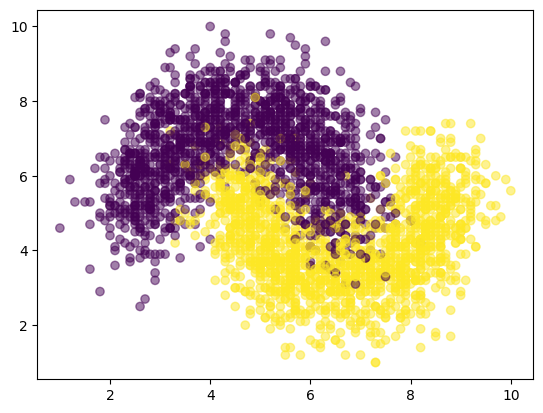

In [10]:
plt.scatter(x='Gene One',y='Gene Two',data=df,c='Cancer Present',alpha=0.5)

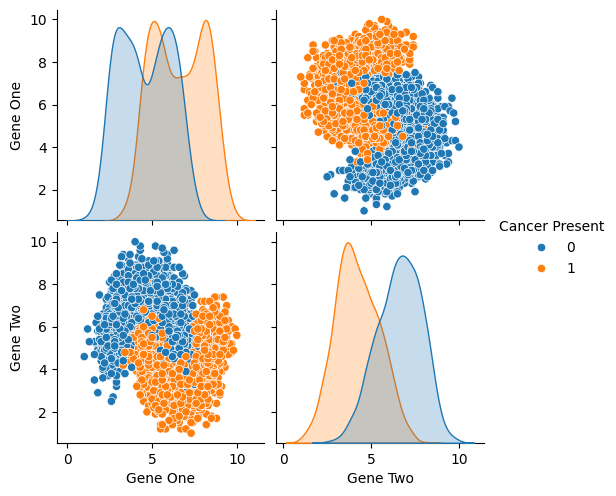

In [13]:
sns.pairplot(data=df,hue='Cancer Present')

In [14]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X=df.drop('Cancer Present',axis=1)
y=df['Cancer Present']

In [18]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.3,random_state=42)

In [20]:
scaler=StandardScaler()
X_train=scaler.fit_transform(X_train)
X_test=scaler.transform(X_test)

In [22]:
from sklearn.neighbors import KNeighborsClassifier

In [23]:
help(KNeighborsClassifier)

Help on class KNeighborsClassifier in module sklearn.neighbors._classification:

class KNeighborsClassifier(sklearn.neighbors._base.KNeighborsMixin, sklearn.base.ClassifierMixin, sklearn.neighbors._base.NeighborsBase)
 |  KNeighborsClassifier(n_neighbors=5, *, weights='uniform', algorithm='auto', leaf_size=30, p=2, metric='minkowski', metric_params=None, n_jobs=None)
 |
 |  Classifier implementing the k-nearest neighbors vote.
 |
 |  Read more in the :ref:`User Guide <classification>`.
 |
 |  Parameters
 |  ----------
 |  n_neighbors : int, default=5
 |      Number of neighbors to use by default for :meth:`kneighbors` queries.
 |
 |  weights : {'uniform', 'distance'}, callable or None, default='uniform'
 |      Weight function used in prediction.  Possible values:
 |
 |      - 'uniform' : uniform weights.  All points in each neighborhood
 |        are weighted equally.
 |      - 'distance' : weight points by the inverse of their distance.
 |        in this case, closer neighbors of a q

In [24]:
k_model=KNeighborsClassifier(n_neighbors=1)

In [25]:
k_model.fit(X_train,y_train)

KNeighborsClassifier(n_neighbors=1)

In [27]:
y_pred=k_model.predict(X_test)

In [28]:
from sklearn.metrics import confusion_matrix,classification_report,ConfusionMatrixDisplay

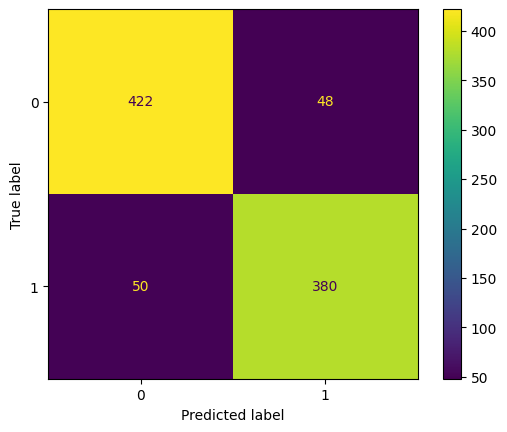

In [29]:
ConfusionMatrixDisplay.from_estimator(k_model,X_test,y_test)

In [33]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.89      0.90      0.90       470
           1       0.89      0.88      0.89       430

    accuracy                           0.89       900
   macro avg       0.89      0.89      0.89       900
weighted avg       0.89      0.89      0.89       900



In [35]:
df['Cancer Present'].value_counts()
#klassarin sayi eynidi, weight default saxlayiriq

,count
Cancer Present,
1,1500
0,1500


In [36]:
from sklearn.metrics import accuracy_score

In [40]:
errors=[]
for k in range(1,30):
  knn_model=KNeighborsClassifier(n_neighbors=k)
  knn_model.fit(X_train,y_train)
  y_preds=knn_model.predict(X_test)
  error=1-accuracy_score(y_test,y_preds)
  errors.append(error)

Text(0, 0.5, 'Error')

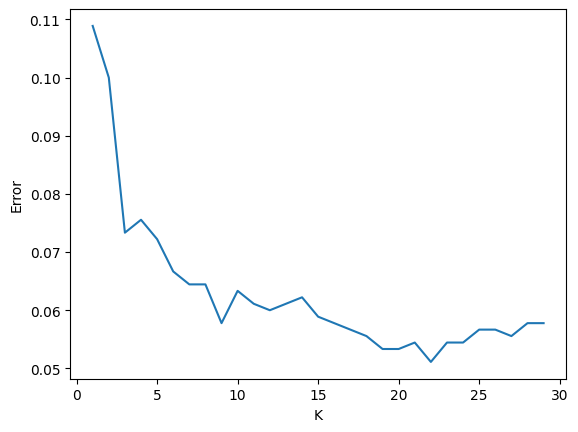

In [47]:
plt.plot(range(1,30),errors)
plt.xlabel('K')
plt.ylabel('Error')

(0.0, 0.11)

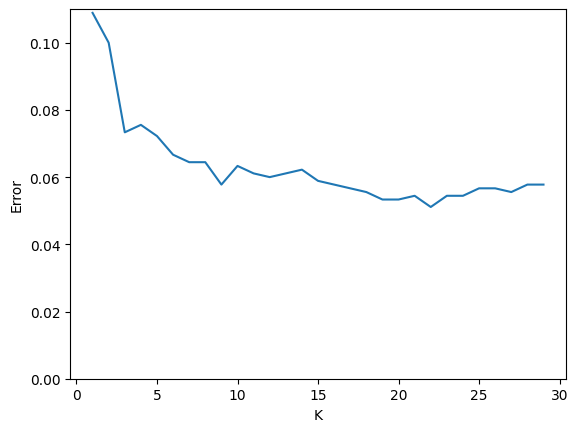

In [48]:
plt.plot(range(1,30),errors)
plt.xlabel('K')
plt.ylabel('Error')
plt.ylim(0,0.11)

# Pipeline

In [49]:
from sklearn.pipeline import Pipeline

In [53]:
knn=KNeighborsClassifier()

In [55]:
knn.get_params().keys()

dict_keys(['algorithm', 'leaf_size', 'metric', 'metric_params', 'n_jobs', 'n_neighbors', 'p', 'weights'])

In [56]:
operations=[('scaler',scaler),('knn',knn)]

In [57]:
pipe=Pipeline(operations)

In [65]:
k_values=list(range(1,20))
k_values

[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]

In [71]:
param_grid={'knn__n_neighbors':k_values}

In [72]:
from sklearn.model_selection import GridSearchCV

In [73]:
full_cv_classifier=GridSearchCV(pipe,param_grid,cv=5,scoring='accuracy')

In [74]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.3,random_state=42)

In [75]:
full_cv_classifier.fit(X_train,y_train)

GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('scaler', StandardScaler()),
                                       ('knn', KNeighborsClassifier())]),
             param_grid={'knn__n_neighbors': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11,
                                              12, 13, 14, 15, 16, 17, 18, 19]},
             scoring='accuracy')

In [76]:
full_cv_classifier.best_estimator_

Pipeline(steps=[('scaler', StandardScaler()),
                ('knn', KNeighborsClassifier(n_neighbors=16))])

In [82]:
full_cv_classifier.best_estimator_.get_params()

{'memory': None,
 'steps': [('scaler', StandardScaler()),
  ('knn', KNeighborsClassifier(n_neighbors=16))],
 'transform_input': None,
 'verbose': False,
 'scaler': StandardScaler(),
 'knn': KNeighborsClassifier(n_neighbors=16),
 'scaler__copy': True,
 'scaler__with_mean': True,
 'scaler__with_std': True,
 'knn__algorithm': 'auto',
 'knn__leaf_size': 30,
 'knn__metric': 'minkowski',
 'knn__metric_params': None,
 'knn__n_jobs': None,
 'knn__n_neighbors': 16,
 'knn__p': 2,
 'knn__weights': 'uniform'}

In [83]:
full_pred=full_cv_classifier.predict(X_test)

In [89]:
print(classification_report(y_test,full_pred))

              precision    recall  f1-score   support

           0       0.94      0.96      0.95       470
           1       0.95      0.93      0.94       430

    accuracy                           0.94       900
   macro avg       0.94      0.94      0.94       900
weighted avg       0.94      0.94      0.94       900



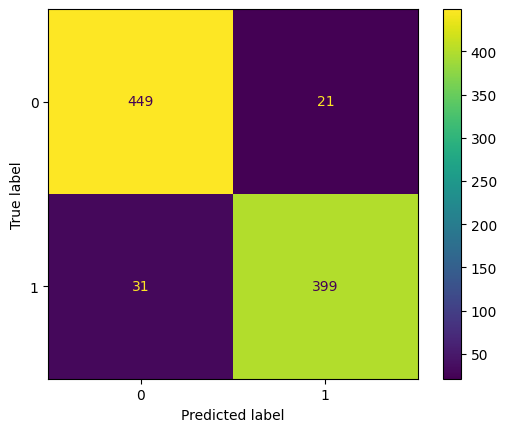

In [90]:
ConfusionMatrixDisplay.from_estimator(full_cv_classifier,X_test,y_test)

In [91]:
new_patient=[[3.8,6.4]]

In [93]:
full_cv_classifier.predict(new_patient)

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


array([0])

In [92]:
full_cv_classifier.predict_proba(new_patient)

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


array([[1., 0.]])